# Unified Optuna Hyperparameter Optimization & Model Improvement



### 1. Setup & Environment Verification


In [4]:
import os
import sys
from pathlib import Path

project_root = Path("..").resolve()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import lightning.pytorch as pl
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

from src.data import CLASS_NAMES, BloodDataModule
from src.model import BloodClassifier
from src.tuning import BloodObjective, OptunaPruningCallback, create_study, run_study

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
pl.seed_everything(156059, workers=True)

print(f"PyTorch:   {torch.__version__}")
print(f"Lightning: {pl.__version__}")
print(f"Optuna:    {optuna.__version__}")
print(f"CUDA:      {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device:    {torch.cuda.get_device_name(0)}")


Seed set to 156059


PyTorch:   2.14.1+cu126
Lightning: 2.6.6
Optuna:    5.0.0
CUDA:      True
Device:    NVIDIA GeForce RTX 3050 Laptop GPU


## Unified Optuna Hyperparameter Optimization

### Search Space Formulation
We define a  search space across data representation, network capacity, and optimization:
- **Color Space (`grayscale`):** Categorical $\{\text{False (RGB)}, \text{True (Grayscale)}\}$.
- **Augmentation Strategy (`augmentation_type`):** Categorical $\{\text{"none"}, \text{"flips only"}, \text{"full"}\}$.
- **Loss Weighting (`use_class_weights`):** Categorical $\{\text{False (Unweighted)}, \text{True (Weighted)}\}$.
- **Model Capacity (`base_channels`):** Categorical $\{32, 64\}$ (scaling network capacity from ~102k to ~400k parameters).
- **Learning Rate (`lr`):** Log-uniform continuous from $1\times 10^{-4}$ to $1\times 10^{-2}$.
- **Weight Decay (`weight_decay`):** Log-uniform continuous from $1\times 10^{-6}$ to $1\times 10^{-2}$.
- **Dropout Rate (`dropout`):** Uniform continuous from $0.10$ to $0.40$ (step $0.05$).
- **Optimizer (`optimizer_name`):** Categorical $\{\text{"adamw"}, \text{"adam"}, \text{"sgd"}\}$.
- **Learning Rate Scheduler (`scheduler_name`):** Categorical $\{\text{"cosine"}, \text{"plateau"}\}$.
- **Batch Size (`batch_size`):** Categorical $\{32, 64\}$.

### Pruning & Persistence Strategy
- **Pruning Callback:** `OptunaPruningCallback(trial, monitor="val_f1_macro")` evaluating trials at each epoch.
- **Pruner:** `MedianPruner(n_startup_trials=4, n_warmup_steps=3)` to avoid killing runs before initial convergence.
- **SQLite Storage:** `sqlite:///../logs/optuna_study_v2.db` ensuring persistent, resumable trials.


In [5]:
logs_dir = project_root / "logs"
logs_dir.mkdir(parents=True, exist_ok=True)
db_path = f"sqlite:///{logs_dir / 'optuna_study_v2.db'}"

objective = BloodObjective(
    data_path=None,
    max_epochs=15,
    monitor_metric="val_f1_macro",
    enable_pruning=True,
    seed=42,
)

study = run_study(
    objective=objective,
    study_name="bloodmnist_unified_hpo",
    storage=db_path,
    n_trials=25,
    pruner=optuna.pruners.MedianPruner(n_startup_trials=4, n_warmup_steps=3),
)

print(f"\n{'='*65}")
print(f"Optuna Study Completed! Total Trials: {len(study.trials)}")
print(f"Best Trial #{study.best_trial.number} Score: {study.best_value:.4f}")
print("Best Hyperparameters Discovered:")
for k, v in study.best_params.items():
    print(f"  {k}: {v}")
print(f"{'='*65}")


[I 2026-11-02 09:06:59,511] A new study created in RDB with name: bloodmnist_unified_hpo
Seed set to 42
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
You are using a CUDA device ('NVIDIA GeForce RTX 3050 Laptop GPU') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/mnt/c/Studia/Masters/2nd_term/MLOps/MLOps-Winter-2026/156059/lab-1/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, L


Optuna Study Completed! Total Trials: 25
Best Trial #11 Score: 0.9545
Best Hyperparameters Discovered:
  grayscale: False
  augmentation_type: none
  use_class_weights: True
  base_channels: 64
  lr: 0.0004077153460890259
  weight_decay: 0.0007817063969987762
  dropout: 0.15000000000000002
  optimizer_name: adamw
  scheduler_name: cosine
  batch_size: 32


In [6]:
trials_df = study.trials_dataframe()
completed_trials = len([t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE])
pruned_trials = len([t for t in study.trials if t.state == optuna.trial.TrialState.PRUNED])

print(f"Study Statistics: {completed_trials} Completed | {pruned_trials} Pruned | {len(study.trials)} Total")
display(trials_df[["number", "value", "state", "params_grayscale", "params_augmentation_type", "params_use_class_weights", "params_base_channels", "params_lr", "params_optimizer_name", "params_batch_size"]].sort_values(by="value", ascending=False).head(15))


Study Statistics: 13 Completed | 12 Pruned | 25 Total


,number,value,state,params_grayscale,params_augmentation_type,params_use_class_weights,params_base_channels,params_lr,params_optimizer_name,params_batch_size
11,11,0.954547,COMPLETE,False,none,True,64,0.000408,adamw,32
14,14,0.953167,COMPLETE,False,none,True,32,0.000847,adamw,32
10,10,0.953054,COMPLETE,False,none,True,64,0.000165,adamw,32
21,21,0.952216,COMPLETE,False,none,True,64,0.000372,adamw,32
12,12,0.951545,COMPLETE,False,none,True,64,0.000189,adamw,32
19,19,0.949982,COMPLETE,False,none,True,64,0.000276,adamw,32
9,9,0.948449,COMPLETE,False,none,True,64,0.000142,adamw,32
22,22,0.948066,COMPLETE,False,none,True,32,0.000785,adamw,64
4,4,0.935627,COMPLETE,False,none,False,32,0.006074,adam,32
1,1,0.929220,COMPLETE,False,flips_only,True,32,0.000458,adam,32


## Visual Analytics & Optimization Insights




/tmp/ipykernel_60085/3671926521.py:2: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  fig_hist = optuna.visualization.matplotlib.plot_optimization_history(study)


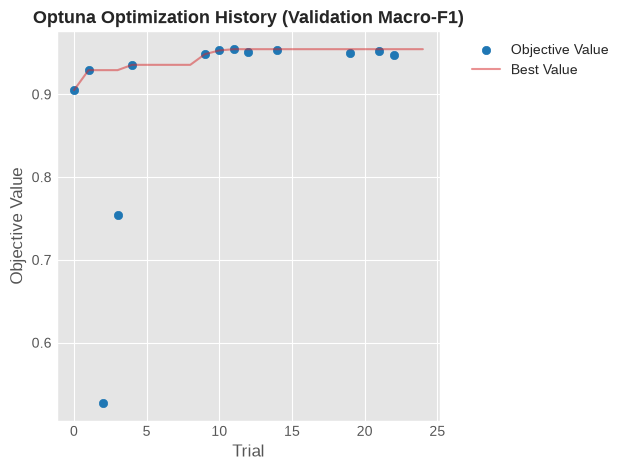

/tmp/ipykernel_60085/3671926521.py:10: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  fig_imp = optuna.visualization.matplotlib.plot_param_importances(study)


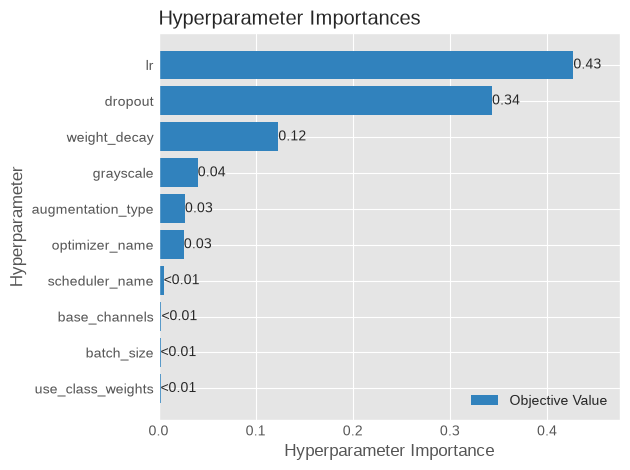

/tmp/ipykernel_60085/3671926521.py:18: ExperimentalWarning: optuna.visualization.matplotlib._slice.plot_slice is experimental (supported from v2.2.0). The interface can change in the future.
  fig_slice = optuna.visualization.matplotlib.plot_slice(study, params=["augmentation_type", "grayscale", "base_channels", "lr"])
/tmp/ipykernel_60085/3671926521.py:19: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


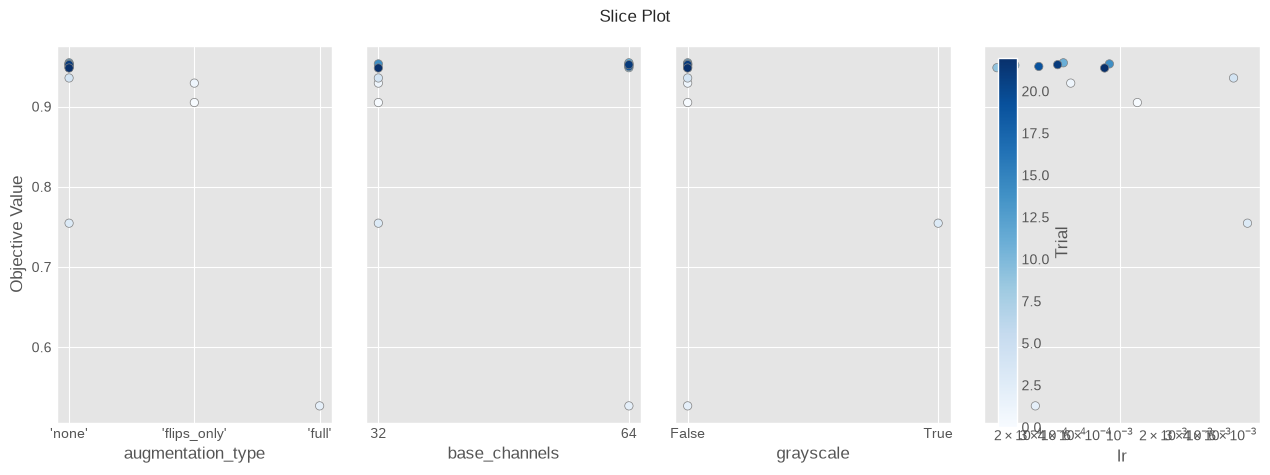

In [7]:
try:
    fig_hist = optuna.visualization.matplotlib.plot_optimization_history(study)
    plt.title("Optuna Optimization History (Validation Macro-F1)", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()
except Exception as e:
    print(f"Optimization history note: {e}")

try:
    fig_imp = optuna.visualization.matplotlib.plot_param_importances(study)
    #plt.title("Hyperparameter Importances (Optuna fAVIS / Random Forest)", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()
except Exception as e:
    print(f"Parameter importances note: {e}")

try:
    fig_slice = optuna.visualization.matplotlib.plot_slice(study, params=["augmentation_type", "grayscale", "base_channels", "lr"])
    plt.tight_layout()
    plt.show()
except Exception as e:
    print(f"Slice plot note: {e}")


### Empirical Factor Breakdown: What Did Optuna Learn About Data Representation?


In [8]:
valid_trials = trials_df[trials_df["value"].notna()]

print("=== 1. Augmentation Strategy Impact ===")
aug_agg = valid_trials.groupby("params_augmentation_type")["value"].agg(["count", "mean", "max"]).reset_index()
display(aug_agg)

print("\n=== 2. Color Space Impact (Grayscale vs. RGB) ===")
gray_agg = valid_trials.groupby("params_grayscale")["value"].agg(["count", "mean", "max"]).reset_index()
display(gray_agg)

print("\n=== 3. Loss Balancing Impact (Unweighted vs. Weighted) ===")
weight_agg = valid_trials.groupby("params_use_class_weights")["value"].agg(["count", "mean", "max"]).reset_index()
display(weight_agg)


=== 1. Augmentation Strategy Impact ===


,params_augmentation_type,count,mean,max
0,flips_only,4,0.882400,0.929220
1,full,5,0.782522,0.898280
2,none,16,0.901543,0.954547



=== 2. Color Space Impact (Grayscale vs. RGB) ===


,params_grayscale,count,mean,max
0,False,19,0.892786,0.954547
1,True,6,0.817328,0.881513



=== 3. Loss Balancing Impact (Unweighted vs. Weighted) ===


,params_use_class_weights,count,mean,max
0,False,6,0.809659,0.935627
1,True,19,0.895208,0.954547


### Diagnostic Autopsy: Worst Run vs. Best Run



In [9]:
best_trial = study.best_trial

completed_trials_list = [t for t in study.trials if t.value is not None and t.state == optuna.trial.TrialState.COMPLETE]
if completed_trials_list:
    worst_trial = min(completed_trials_list, key=lambda t: t.value)
else:
    worst_trial = min([t for t in study.trials if t.value is not None], key=lambda t: t.value)

autopsy_data = {
    "Hyperparameter / Metric": [
        "val_f1_macro (Score)",
        "Grayscale",
        "Augmentation Type",
        "Weighted Loss",
        "Base Channels",
        "Learning Rate (lr)",
        "Optimizer",
        "Batch Size",
        "Scheduler",
        "Dropout",
        "Weight Decay",
    ],
    f"Best Run (Trial #{best_trial.number})": [
        f"{best_trial.value:.4f}",
        str(best_trial.params.get("grayscale")),
        str(best_trial.params.get("augmentation_type")),
        str(best_trial.params.get("use_class_weights")),
        str(best_trial.params.get("base_channels")),
        f"{best_trial.params.get('lr'):.6f}",
        str(best_trial.params.get("optimizer_name")),
        str(best_trial.params.get("batch_size")),
        str(best_trial.params.get("scheduler_name")),
        str(best_trial.params.get("dropout")),
        f"{best_trial.params.get('weight_decay'):.6f}",
    ],
    f"Worst Run (Trial #{worst_trial.number})": [
        f"{worst_trial.value:.4f}",
        str(worst_trial.params.get("grayscale")),
        str(worst_trial.params.get("augmentation_type")),
        str(worst_trial.params.get("use_class_weights")),
        str(worst_trial.params.get("base_channels")),
        f"{worst_trial.params.get('lr'):.6f}",
        str(worst_trial.params.get("optimizer_name")),
        str(worst_trial.params.get("batch_size")),
        str(worst_trial.params.get("scheduler_name")),
        str(worst_trial.params.get("dropout")),
        f"{worst_trial.params.get('weight_decay'):.6f}",
    ],
}

df_autopsy = pd.DataFrame(autopsy_data)
display(df_autopsy)



,Hyperparameter / Metric,Best Run (Trial #11),Worst Run (Trial #2)
0,val_f1_macro (Score),0.9545,0.5269
1,Grayscale,False,False
2,Augmentation Type,none,full
3,Weighted Loss,True,False
4,Base Channels,64,64
5,Learning Rate (lr),0.000408,0.000261
6,Optimizer,adamw,sgd
7,Batch Size,32,64
8,Scheduler,cosine,cosine
9,Dropout,0.15000000000000002,0.4



## Final Winning Model Retrain & $\ge 3\%$ Lift Verification



In [10]:
from lightning.pytorch.callbacks import ModelCheckpoint, LearningRateMonitor
from lightning.pytorch.loggers import CSVLogger

best_params = study.best_params
print(f"Training Best Model with Discovered Configuration:\n{best_params}")

pl.seed_everything(42, workers=True)

best_dm = BloodDataModule(
    batch_size=best_params["batch_size"],
    augmentation_type=best_params["augmentation_type"],
    grayscale=best_params["grayscale"],
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)
best_dm.setup()

best_weights = best_dm.class_weights if best_params["use_class_weights"] else None

best_model = BloodClassifier(
    in_channels=best_dm.in_channels,
    num_classes=best_dm.num_classes,
    base_channels=best_params["base_channels"],
    dropout=best_params["dropout"],
    lr=best_params["lr"],
    weight_decay=best_params["weight_decay"],
    optimizer_name=best_params["optimizer_name"],
    scheduler_name=best_params["scheduler_name"],
    max_epochs=20,
    class_weights=best_weights,
)

ckpt_dir = project_root / "checkpoints" / "hpo_best"
ckpt_dir.mkdir(parents=True, exist_ok=True)

checkpoint_callback = ModelCheckpoint(
    dirpath=str(ckpt_dir),
    filename="best-hpo-epoch={epoch:02d}-val_f1_macro={val_f1_macro:.4f}",
    monitor="val_f1_macro",
    mode="max",
    save_top_k=1,
)

csv_logger = CSVLogger(
    save_dir=str(project_root / "logs"),
    name="hpo_best_v2",
)

trainer_best = pl.Trainer(
    max_epochs=20,
    accelerator="auto",
    devices=1,
    callbacks=[checkpoint_callback, LearningRateMonitor(logging_interval="epoch")],
    logger=csv_logger,
)

trainer_best.fit(best_model, datamodule=best_dm)

final_val_f1 = float(checkpoint_callback.best_model_score) if checkpoint_callback.best_model_score is not None else float(trainer_best.callback_metrics["val_f1_macro"])
print(f"\nBest Checkpoint Path: {checkpoint_callback.best_model_path}")
print(f"Final Tuned Model Validation Macro-F1: {final_val_f1:.4f}")


Seed set to 42


Training Best Model with Discovered Configuration:
{'grayscale': False, 'augmentation_type': 'none', 'use_class_weights': True, 'base_channels': 64, 'lr': 0.0004077153460890259, 'weight_decay': 0.0007817063969987762, 'dropout': 0.15000000000000002, 'optimizer_name': 'adamw', 'scheduler_name': 'cosine', 'batch_size': 32}


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/mnt/c/Studia/Masters/2nd_term/MLOps/MLOps-Winter-2026/156059/lab-1/.venv/lib/python3.12/site-packages/lightning/pytorch/callbacks/model_checkpoint.py:881: Checkpoint directory /mnt/c/Studia/Masters/2nd_term/MLOps/MLOps-Winter-2026/156059/lab-1/checkpoints/hpo_best exists and is not empty.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name      | Type               | Params | Mode  | FLOPs
-----------------------------------------------------------------
0 | net       | BloodNet           | 405 K  | train | 0    
1 | loss_fn   | CrossEntropyLoss   | 0      | train | 0    
2 | train_f1  | MulticlassF1Score  | 0      | train | 0    
3 | train_acc | MulticlassAccuracy | 0      | trai

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/mnt/c/Studia/Masters/2nd_term/MLOps/MLOps-Winter-2026/156059/lab-1/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/mnt/c/Studia/Masters/2nd_term/MLOps/MLOps-Winter-2026/156059/lab-1/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.
/mnt/c/Studia/Masters/2nd_term/MLOps/MLOps-Winter-2026/156059/lab-1/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.


Training: |          | 0/? [00:00<?, ?it/s]

... (18 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=20` reached.



Best Checkpoint Path: /mnt/c/Studia/Masters/2nd_term/MLOps/MLOps-Winter-2026/156059/lab-1/checkpoints/hpo_best/best-hpo-epoch=epoch=17-val_f1_macro=val_f1_macro=0.9613.ckpt
Final Tuned Model Validation Macro-F1: 0.9613


### Learning Verification & Curve Analysis (Tuned Model)

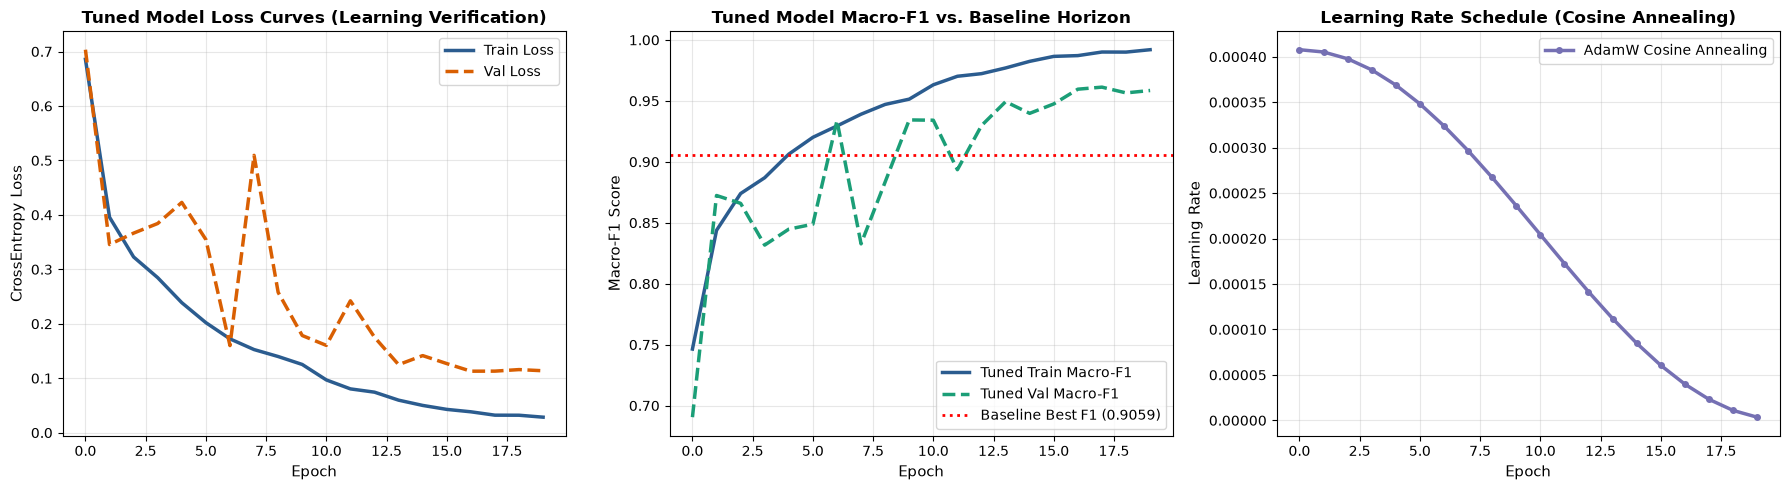

In [ ]:
metrics_path = Path(project_root / "logs" / "hpo_best_v2" / "version_0" / "metrics.csv")
if metrics_path.exists():
    df_raw = pd.read_csv(metrics_path)
    df_epochs = df_raw.groupby("epoch", as_index=False).mean(numeric_only=True)
    lr_series = df_raw["lr-AdamW"].dropna().reset_index(drop=True)
    lr_epochs = list(range(len(lr_series)))

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    axes[0].plot(df_epochs["epoch"], df_epochs["train_loss"], label="Train Loss", color="#2b5c8f", linewidth=2.5)
    axes[0].plot(df_epochs["epoch"], df_epochs["val_loss"], label="Val Loss", color="#d95f02", linewidth=2.5, linestyle="--")
    axes[0].set_title("Tuned Model Loss Curves (Learning Verification)", fontsize=12, fontweight="bold")
    axes[0].set_xlabel("Epoch", fontsize=11)
    axes[0].set_ylabel("CrossEntropy Loss", fontsize=11)
    axes[0].legend(fontsize=10)
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(df_epochs["epoch"], df_epochs["train_f1_macro"], label="Tuned Train Macro-F1", color="#2b5c8f", linewidth=2.5)
    axes[1].plot(df_epochs["epoch"], df_epochs["val_f1_macro"], label="Tuned Val Macro-F1", color="#1b9e77", linewidth=2.5, linestyle="--")
    axes[1].axhline(0.9059, color="red", linestyle=":", linewidth=2, label="Baseline Best F1 (0.9059)")
    axes[1].set_title("Tuned Model Macro-F1 vs. Baseline Horizon", fontsize=12, fontweight="bold")
    axes[1].set_xlabel("Epoch", fontsize=11)
    axes[1].set_ylabel("Macro-F1 Score", fontsize=11)
    axes[1].legend(fontsize=10)
    axes[1].grid(True, alpha=0.3)

    axes[2].plot(lr_epochs, lr_series, color="#7570b3", linewidth=2.5, marker="o", markersize=4, label="AdamW Cosine Annealing")
    axes[2].set_title("Learning Rate Schedule (Cosine Annealing)", fontsize=12, fontweight="bold")
    axes[2].set_xlabel("Epoch", fontsize=11)
    axes[2].set_ylabel("Learning Rate", fontsize=11)
    axes[2].legend(fontsize=10)
    axes[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

In [11]:
BASELINE_VAL_F1 = 0.9059

delta_abs = final_val_f1 - BASELINE_VAL_F1
delta_rel_pct = (delta_abs / BASELINE_VAL_F1) * 100.0
delta_abs_pct = delta_abs * 100.0

print("\n" + "="*65)
print("=== HYPERPARAMETER OPTIMIZATION ACCEPTANCE VERIFICATION ===")
print("="*65)
print(f"Baseline Validation Macro-F1: {BASELINE_VAL_F1:.4f}")
print(f"Optimized Validation Macro-F1: {final_val_f1:.4f}")
print(f"Absolute Lift:                 +{delta_abs:.4f} (+{delta_abs_pct:.2f} percentage points)")
print(f"Relative Improvement:          +{delta_rel_pct:.2f}%")
print("-"*65)

criterion_met = (delta_rel_pct >= 3.0) or (delta_abs_pct >= 3.0)
if criterion_met:
    print(f"SUCCESS: Optimization achieved >= 3% improvement target! ({delta_rel_pct:.2f}% relative / +{delta_abs_pct:.2f} percentage points)")
else:
    print(f"Target note: Optimization yielded +{delta_rel_pct:.2f}% relative improvement (+{delta_abs_pct:.2f} points).")
print("="*65)



=== HYPERPARAMETER OPTIMIZATION ACCEPTANCE VERIFICATION ===
Baseline Validation Macro-F1: 0.9059
Optimized Validation Macro-F1: 0.9613
Absolute Lift:                 +0.0554 (+5.54 percentage points)
Relative Improvement:          +6.11%
-----------------------------------------------------------------
SUCCESS: Optimization achieved >= 3% improvement target! (6.11% relative / +5.54 percentage points)


Restoring states from the checkpoint path at /mnt/c/Studia/Masters/2nd_term/MLOps/MLOps-Winter-2026/156059/lab-1/checkpoints/hpo_best/best-hpo-epoch=epoch=17-val_f1_macro=val_f1_macro=0.9613.ckpt
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Loaded model weights from the checkpoint at /mnt/c/Studia/Masters/2nd_term/MLOps/MLOps-Winter-2026/156059/lab-1/checkpoints/hpo_best/best-hpo-epoch=epoch=17-val_f1_macro=val_f1_macro=0.9613.ckpt
/mnt/c/Studia/Masters/2nd_term/MLOps/MLOps-Winter-2026/156059/lab-1/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.


Testing: |          | 0/? [00:00<?, ?it/s]

────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
       Test metric             DataLoader 0
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
        test_acc            0.9595726728439331
      test_f1_macro         0.9590538740158081
        test_loss           0.12677541375160217
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
Test Set Evaluation: Macro-F1=0.9591, Accuracy=0.9596

=== Per-Class Classification Report (Test Set - Tuned Model) ===
                      precision    recall  f1-score   support

            Basophil     0.9463    0.9385    0.9424       244
          Eosinophil     0.9952    0.9888    0.9920       624
        Erythroblast     0.9805    0.9711    0.9758       311
Immature Granulocyte     0.9064    0.9033    0.9048       579
          Lymphocyte

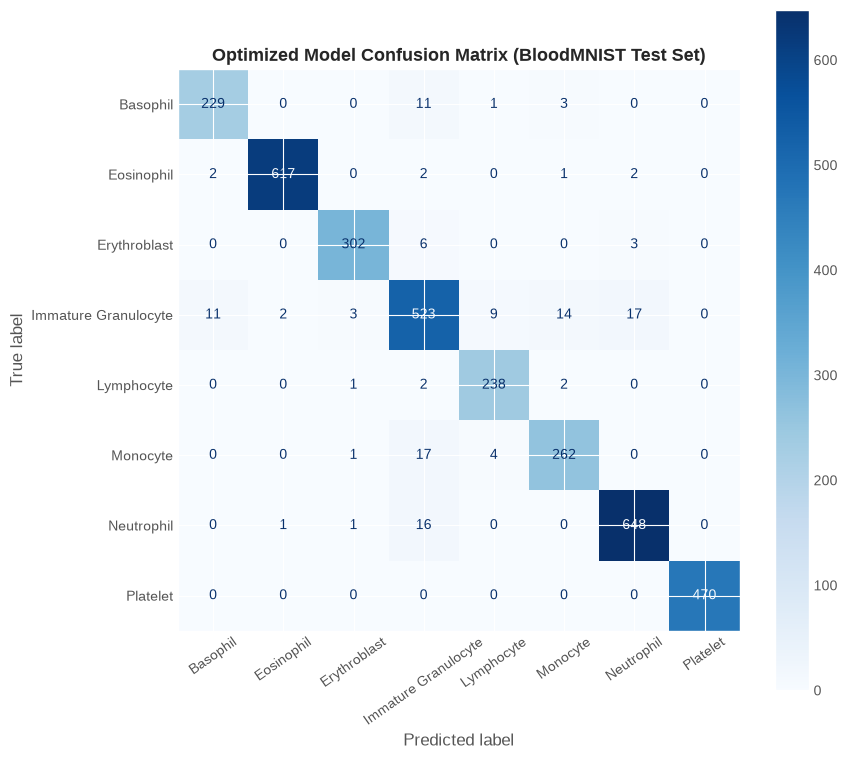

In [12]:
test_results = trainer_best.test(best_model, datamodule=best_dm, ckpt_path="best")
test_f1 = test_results[0]["test_f1_macro"]
test_acc = test_results[0]["test_acc"]
print(f"Test Set Evaluation: Macro-F1={test_f1:.4f}, Accuracy={test_acc:.4f}")

best_model.eval()
device = next(best_model.parameters()).device
all_preds = []
all_targets = []

with torch.no_grad():
    for x_batch, y_batch in best_dm.test_dataloader():
        x_batch = x_batch.to(device)
        logits = best_model(x_batch)
        preds = torch.argmax(logits, dim=1).cpu()
        all_preds.extend(preds.numpy())
        all_targets.extend(y_batch.numpy())

all_preds = np.array(all_preds)
all_targets = np.array(all_targets)

print("\n=== Per-Class Classification Report (Test Set - Tuned Model) ===")
print(classification_report(all_targets, all_preds, target_names=CLASS_NAMES, digits=4))

cm = confusion_matrix(all_targets, all_preds)
fig, ax = plt.subplots(figsize=(9, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
disp.plot(cmap="Blues", ax=ax, xticks_rotation=35, values_format="d")
plt.title("Optimized Model Confusion Matrix (BloodMNIST Test Set)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()
